## Fine tunning Bert para Clasificación

---

Anteriormente utilizamos un modelo para la generación de texto nuevo; ahora, en cambio, trabajaremos en el *fine-tuning* de un modelo enfocado en la **clasificación**.

En concreto, construiremos una arquitectura de Deep Learning compuesta principalmente por un modelo **BERT preentrenado** (el cual no está diseñado para generar texto). A este le adjuntaremos una nueva capa final con dos únicas salidas, correspondientes a dos categorías: **valoraciones positivas o negativas** de diferentes películas.

El objetivo principal será lograr que este modelo analice reseñas o textos breves y prediga si a una persona le ha gustado o no la película.

In [ ]:
from datasets import load_dataset, DatasetDict

# Cargar el dataset utilizando el namespace correcto
dataset = load_dataset('stanfordnlp/imdb')

README.md:   0%|          | 0.00/7.81k [00:00<?, ?B/s]

plain_text/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 21.0MB            

plain_text/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 20.5MB            

plain_text/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/unsupervised-00000-of-00001.p(…): reconstructing file:   0%|          |  0.00B / 42.0MB            

plain_text/unsupervised-00000-of-00001.p(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating unsupervised split:   0%|          | 0/50000 [00:00<?, ? examples/s]

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import DataLoader

In [ ]:
# librerías de huggingface
from transformers import BertModel, BertTokenizer

In [ ]:
# GPU
device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')

tokenizer = BertTokenizer.from_pretrained('bert-base-uncased')
bert = BertModel.from_pretrained('bert-base-uncased').to(device)

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


In [ ]:
bert # vemos el shape de la capa final

BertModel(
  (embeddings): BertEmbeddings(
    (word_embeddings): Embedding(30522, 768, padding_idx=0)
    (position_embeddings): Embedding(512, 768)
    (token_type_embeddings): Embedding(2, 768)
    (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True)
    (dropout): Dropout(p=0.1, inplace=False)
  )
  (encoder): BertEncoder(
    (layer): ModuleList(
      (0-11): 12 x BertLayer(
        (attention): BertAttention(
          (self): BertSelfAttention(
            (query): Linear(in_features=768, out_features=768, bias=True)
            (key): Linear(in_features=768, out_features=768, bias=True)
            (value): Linear(in_features=768, out_features=768, bias=True)
            (dropout): Dropout(p=0.1, inplace=False)
          )
          (output): BertSelfOutput(
            (dense): Linear(in_features=768, out_features=768, bias=True)
            (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True)
            (dropout): Dropout(p=0.1, inplace=False)
  

Al examinar la arquitectura, encontramos los *word embeddings* y *position embeddings*, que equivalen a los WTE y WPE de OpenAI. Además, disponemos de una matriz más pequeña llamada *token type embeddings* (de 2 por 768, con la misma dimensión de embeddings pero limitada a dos opciones), diseñada para diferenciar entre distintos tipos de tokens y útil para entrenar tareas como preguntas y respuestas o diversas categorizaciones.

A continuación, llegamos a lo que BERT denomina *encoder* (`BertEncoder`), el cual integra el transformador junto con sus 12 bloques. En estos bloques de atención, la matriz densa corresponde a lo que llamamos $W_0$ o matriz de mezcla lineal. Asimismo, se encuentra el bloque MLP —llamado *intermediate* por el modelo—, que consiste en una capa lineal de 768 por 3072 (una expansión de 4x con una activación GELU) seguida de su respectiva contracción mediante otra capa densa (*dense*).

Por último, cabe destacar que al final del modelo no hay ninguna matriz que se expanda hasta las 30,000 dimensiones del vocabulario de tokens; por lo tanto, se trata simplemente de una capa de agrupación final.

In [ ]:
bert.embeddings.dropout.p

0.1

In [ ]:
tokenizer.vocab_size

30522

Mas inputs y outpus del modelo

In [ ]:
# Cuando usamos el encode solo vemos los tokens convertidos a un tensor de pytorch

text = 'Replace me with any text you like.'
tokens = tokenizer.encode(text, return_tensors='pt').to(device)
tokens

tensor([[ 101, 5672, 2033, 2007, 2151, 3793, 2017, 2066, 1012,  102]],
       device='cuda:0')

In [ ]:
# cuando pasmos solo el texto sin encode podemos observar los inputs IDs y las salidas de la mascara de atención (siempre seran todas uno cuando tenemos una pieza de texto que seria 1 lote )

text = 'Replace me with any text you like.'
tokens = tokenizer(text, return_tensors='pt').to(device)
tokens

{'input_ids': tensor([[ 101, 5672, 2033, 2007, 2151, 3793, 2017, 2066, 1012,  102]],
       device='cuda:0'), 'token_type_ids': tensor([[0, 0, 0, 0, 0, 0, 0, 0, 0, 0]], device='cuda:0'), 'attention_mask': tensor([[1, 1, 1, 1, 1, 1, 1, 1, 1, 1]], device='cuda:0')}

In [ ]:
# obtener la salida del modelo utilizando entradas específicas
output = bert(
    input_ids      = tokens['input_ids'],
    attention_mask = tokens['attention_mask']
)

In [ ]:
# pero esta es una forma mejor equivalente a la anterior

output = bert(**tokens) # sin * aparece un error

In [ ]:
dir(output)

['__annotations__',
 '__class__',
 '__class_getitem__',
 '__contains__',
 '__dataclass_fields__',
 '__dataclass_params__',
 '__delattr__',
 '__delitem__',
 '__dict__',
 '__dir__',
 '__doc__',
 '__eq__',
 '__firstlineno__',
 '__format__',
 '__ge__',
 '__getattribute__',
 '__getitem__',
 '__getstate__',
 '__gt__',
 '__hash__',
 '__init__',
 '__init_subclass__',
 '__ior__',
 '__iter__',
 '__le__',
 '__len__',
 '__lt__',
 '__match_args__',
 '__module__',
 '__ne__',
 '__new__',
 '__or__',
 '__post_init__',
 '__reduce__',
 '__reduce_ex__',
 '__replace__',
 '__repr__',
 '__reversed__',
 '__ror__',
 '__setattr__',
 '__setitem__',
 '__sizeof__',
 '__static_attributes__',
 '__str__',
 '__subclasshook__',
 'attentions',
 'clear',
 'copy',
 'cross_attentions',
 'fromkeys',
 'get',
 'hidden_states',
 'items',
 'keys',
 'last_hidden_state',
 'move_to_end',
 'past_key_values',
 'pooler_output',
 'pop',
 'popitem',
 'setdefault',
 'to_tuple',
 'update',
 'values']

podemos ver que hay varios metodos y propiedades asociadios a la salida de este modelo Bert.

In [ ]:
output['last_hidden_state'].shape

torch.Size([1, 10, 768])

In [ ]:
output['pooler_output'].shape

torch.Size([1, 768])

In [ ]:
# ¿podemos obtener una salida de texto?
# bert.generate(tokens, max_length=100, do_sample=True).cpu()

---

La respuesta es no. Este modelo en particular no incluye ningún atributo `generate`; es una capacidad que tendría que incorporarse explícitamente. En teoría, podríamos modificarlo para que genere tokens, pero no es así como está configurado por defecto.

De hecho, la forma más sencilla de hacerlo —aunque no sea para lo que el modelo fue entrenado originalmente— consistiría en definir un nuevo método que tome los *embeddings* de palabras, transponga esa matriz y la acople al final del método *pooler* sin la tanh.

En su lugar se creara un modelo que utiliza Bert pre entrenado con una nueva cabeza en la parte superior que hace la clasificación

In [ ]:
class BertForBinaryClassification(nn.Module):
    def __init__(self, num_labels=2):
        super(BertForBinaryClassification, self).__init__()

        # Cargar el modelo BERT preentrenado desde hugginface
        self.bert = BertModel.from_pretrained('bert-base-uncased')

        # Cabeza de clasificación que convierte la salida de 768 dimensiones a 2 salidas
        self.classifier = nn.Linear(768, num_labels)
        self.dropout = nn.Dropout(self.bert.embeddings.dropout.p)  # 10%

        # Inicializar los pesos y sesgos
        nn.init.xavier_uniform_(self.classifier.weight)
        nn.init.zeros_(self.classifier.bias)

    def forward(self, input_ids, attention_mask=None, token_type_ids=None):
        # Paso hacia adelante a través del BERT descargado (preentrenado)
        outputs = self.bert(
            input_ids      = input_ids,
            attention_mask = attention_mask,
            token_type_ids = token_type_ids
        )

        # Extraer la salida agrupada y aplicar dropout
        pooled_output = self.dropout(outputs.pooler_output)

        # Impulso final a través de la capa de clasificación
        logits = self.classifier(pooled_output)

        return logits

In [ ]:
# crear una instancia del modelo y probarlo
model = BertForBinaryClassification().to(device)

# probar la salida
tokens = tokenizer(text, return_tensors='pt').to(device)
out = model(**tokens)
out

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


tensor([[-0.2973, -0.0157]], device='cuda:0', grad_fn=<AddmmBackward0>)

In [ ]:
# la salida son 2 posibilidades y vamos a entrenarlo para que nos de una positiva y una negativia en cuanto a reseñas de peliculas

## Visualizar el Dataset

In [ ]:
dataset

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 25000
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 25000
    })
    unsupervised: Dataset({
        features: ['text', 'label'],
        num_rows: 50000
    })
})

In [ ]:
dataset['train'][2400] # escogemos en train el numero que queramos ver de los datos

{'text': 'A film so insecure the creaters perhaps hoped to milk an original film noir classic title, "Farewell My Lovely", thinking the gullible would assume it a remake. The characters are so foul and unappealing that it deserved its cold reception when first released. Time only adds to it its absurdity. Having none of the guile, cinematography, desperation or despair of classic noir it relied instead on a convoluted and senseless crime plot that would have easily resulted in several arrests within hours. As if that weren\'t enough it threw in an utterly sexless attempt at erotica in which at least one of the participants hadn\'t bothered to bathe in several days. This only made this mess all the more painful to watch. Find a good classic forties or fifties film noir instead of wasting two hours on this failure.',
 'label': 0}

In [ ]:
# Para ver las características (features) del dataset, debemos acceder primero a una partición (split) como 'train'
dataset['train'].features['label']

ClassLabel(names=['neg', 'pos'])

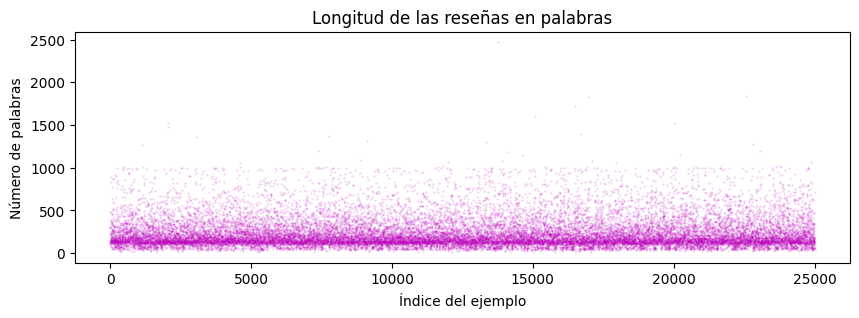

In [ ]:
# Calcular la longitud en palabras de cada reseña en el set de entrenamiento
lengths = [len(text.split()) for text in dataset['train']['text']]

plt.figure(figsize=(10, 3))
plt.plot(lengths, 'm.', markersize=1, alpha=0.2)

plt.gca().set(title='Longitud de las reseñas en palabras', xlabel='Índice del ejemplo', ylabel='Número de palabras')
plt.show()

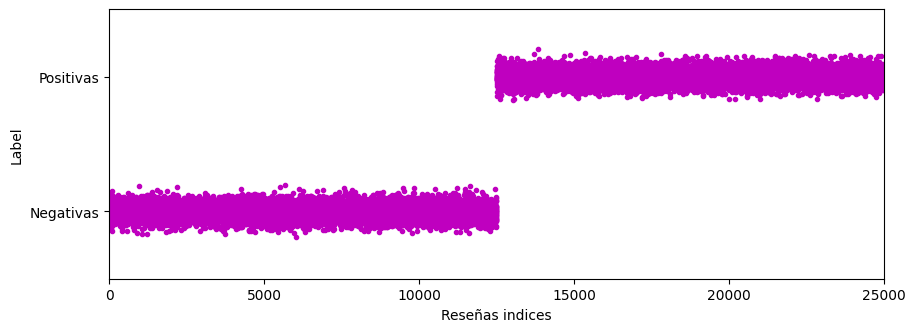

In [ ]:
# Configurar el tamaño de la figura
plt.figure(figsize=(10, 3.5))

# Graficar las etiquetas con un pequeño ruido aleatorio para evitar superposiciones (puntos magenta)
plt.plot(dataset['train']['label'] + np.random.randn(len(dataset['train'])) / 20, 'm.')

# Configurar los ejes, etiquetas y leyendas
plt.gca().set(
    xlabel='Reseñas indices',
    ylabel='Label',
    yticks=[0, 1],
    yticklabels=['Negativas', 'Positivas'],
    xlim=[0, len(dataset['train'])],
    ylim=[-.5, 1.5]
)

# Mostrar la visualización
plt.show()

In [ ]:
# Importante hacer shuffle siempre en este tipo de datasets

### ¿Por qué no conviene entrenar con las reseñas negativas primero?

Entrenar un modelo alimentándolo con bloques ordenados (primero todas las reseñas negativas y luego todas las positivas) afecta gravemente el aprendizaje por las siguientes razones:

* **Olvido catastrófico y sesgo:** El optimizador ajustará todos los pesos para predecir únicamente la primera clase que recibe. Al cambiar abruptamente a la segunda categoría, el modelo sufrirá un "choque" y desaprenderá lo anterior.

* **Inestabilidad e inestabilidad del *Loss*:** Los cambios drásticos en la distribución de las etiquetas entre lotes consecutivos generan fluctuaciones violentas en la función de pérdida, incrementando el riesgo de errores numéricos (como gradientes explosivos o `NaN`).

* **Dificultad de convergencia:** El modelo batallará para encontrar un mínimo global estable porque los gradientes tirarán hacia direcciones opuestas de manera muy polarizada en cada fase.

*Por esta razón, es una regla de oro **mezclar (*shuffle*)** el dataset antes de crear los lotes (*batches*), asegurando que cada iteración contenga una muestra equilibrada de ambas clases.*

In [ ]:
dataset['train'].select(range(100))

Dataset({
    features: ['text', 'label'],
    num_rows: 100
})

In [ ]:
# reducir el tamaño del conjunto de datos mientras:
# 1) se incluyen ambas categorías (ver el gráfico de arriba y el range() de abajo)
# 2) se conservan únicamente 'train' y 'test'
# 3) se utiliza un DatasetDict (no un diccionario de Python) para preservar los métodos
small_data = DatasetDict({split: dataset[split].select(range(10000, 15000)) for split in ['train', 'test']})
small_data

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 5000
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 5000
    })
})

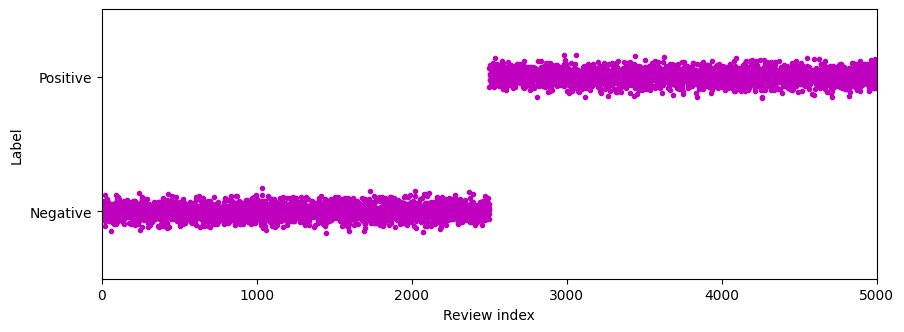

In [ ]:
# confirmar que todavía tenemos ambas categorías
plt.figure(figsize=(10, 3.5))
plt.plot(small_data['train']['label'] + np.random.randn(len(small_data['train'])) / 20, 'm.')
plt.gca().set(
    xlabel='Review index',
    ylabel='Label',
    yticks=[0, 1],
    yticklabels=['Negative', 'Positive'],
    xlim=[0, len(small_data['train'])],
    ylim=[-.5, 1.5]
)
plt.show()

Verificación de categorías: Al igual que hicimos con el dataset completo, este gráfico de dispersión confirma visualmente que el subconjunto recortado contiene tanto las reseñas negativas (primera mitad) como las positivas (segunda mitad), permitiendo entrenar con datos balanceados pero en menor escala para optimizar los tiempos de cómputo.

---

Lo que queremos ahora es preparar los datos para el entrenamiento en el clasificador BERT. Necesitamos tokenizar el texto; sin embargo, en este dataset en concreto las secuencias son de longitud variable. Esto significa que una reseña tendrá un número de tokens diferente al de otra, por lo que debemos solucionarlo, ya que los modelos de lenguaje no están diseñados para manejar lotes con secuencias de distinta longitud. Por lo tanto, cada fila dentro de un lote (*batch*) debe tener exactamente el mismo número de secuencias.

In [ ]:
# ahora si es maxima 512 lo va a cortar

In [ ]:
# esto funciona...
first_try = tokenizer(dataset['train'][0]['text'])

# pero esto es mejor porque las reseñas tienen diferentes longitudes
better = tokenizer(
    dataset['train'][0]['text'], # el texto a tokenizar
    max_length = 512,            # longitud máxima establecida
    padding = 'max_length',      # usar el token de relleno para alcanzar la longitud máxima
    truncation = True)           # recortar los tokens que superen la longitud máxima

print(f"Tokenización 'ingenua' (N={len(first_try['input_ids'])}):")
print(f"{first_try['input_ids']}")

print(f"\nTokenización mejorada (N={len(better['input_ids'])}):")
print(f"{better['input_ids']}")

Tokenización 'ingenua' (N=363):
[101, 1045, 12524, 1045, 2572, 8025, 1011, 3756, 2013, 2026, 2678, 3573, 2138, 1997, 2035, 1996, 6704, 2008, 5129, 2009, 2043, 2009, 2001, 2034, 2207, 1999, 3476, 1012, 1045, 2036, 2657, 2008, 2012, 2034, 2009, 2001, 8243, 2011, 1057, 1012, 1055, 1012, 8205, 2065, 2009, 2412, 2699, 2000, 4607, 2023, 2406, 1010, 3568, 2108, 1037, 5470, 1997, 3152, 2641, 1000, 6801, 1000, 1045, 2428, 2018, 2000, 2156, 2023, 2005, 2870, 1012, 1026, 7987, 1013, 1028, 1026, 7987, 1013, 1028, 1996, 5436, 2003, 8857, 2105, 1037, 2402, 4467, 3689, 3076, 2315, 14229, 2040, 4122, 2000, 4553, 2673, 2016, 2064, 2055, 2166, 1012, 1999, 3327, 2016, 4122, 2000, 3579, 2014, 3086, 2015, 2000, 2437, 2070, 4066, 1997, 4516, 2006, 2054, 1996, 2779, 25430, 14728, 2245, 2055, 3056, 2576, 3314, 2107, 2004, 1996, 5148, 2162, 1998, 2679, 3314, 1999, 1996, 2142, 2163, 1012, 1999, 2090, 4851, 8801, 1998, 6623, 7939, 4697, 3619, 1997, 8947, 2055, 2037, 10740, 2006, 4331, 1010, 2016, 2038, 3348, 200

In [33]:
# definir una función de tokenización que procese cada muestra de datos
def tokenize_function(one_sample):
    return tokenizer(
        one_sample['text'],
        max_length = 512,      # Longitud máxima de secuencia
        padding = 'max_length',# Rellenar secuencias hasta la longitud máxima
        truncation = True)     # Truncar secuencias más largas que max_length

Tokenizamos cada reseña en nuestro dataset (en lote) tenemos ahora en las caracteristicas text, label, input_ids, token_type_ids y atenttion mask ya no necestiamos la columna text ya que el modelo procesa los tokens numericos.

In [34]:
# aplicar la función de tokenización al conjunto de datos (por lotes para mayor eficiencia)
tokenized_dataset = small_data.map(tokenize_function, batched=True)
tokenized_dataset

Map:   0%|          | 0/5000 [00:00<?, ? examples/s]

Map:   0%|          | 0/5000 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['text', 'label', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 5000
    })
    test: Dataset({
        features: ['text', 'label', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 5000
    })
})

In [35]:
# eliminar la columna de texto original
tokenized_dataset = tokenized_dataset.remove_columns(['text'])

# cambiar el formato del conjunto de datos a tensores de PyTorch
tokenized_dataset.set_format('torch', columns=['input_ids', 'attention_mask', 'label'])

# crear DataLoaders para el entrenamiento y la prueba
train_dataloader = DataLoader(tokenized_dataset['train'], shuffle=True, batch_size=8)
test_dataloader = DataLoader(tokenized_dataset['test'], batch_size=32)

Y se pudo crear el DataLoader esta es la realidad de como trabajar con datos reales que no han sido procesados a menudo requieren una cuidadosa comprobación.

In [36]:
# verificar la estructura del conjunto de datos nuevamente
print(tokenized_dataset, '\n\n')

DatasetDict({
    train: Dataset({
        features: ['label', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 5000
    })
    test: Dataset({
        features: ['label', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 5000
    })
}) 




In [37]:
# tokenized_dataset['train'][1000]

# y comprobar una iteración del dataloader
X = next(iter(train_dataloader))
X

{'label': tensor([1, 0, 1, 1, 0, 0, 1, 0]),
 'input_ids': tensor([[  101,  2023,  2003,  ..., 16329,  5896,   102],
         [  101,  2054,  3047,  ..., 20386,  2105,   102],
         [  101,  2023,  2003,  ...,     0,     0,     0],
         ...,
         [  101,  2004,  1037,  ...,     0,     0,     0],
         [  101,  1045,  1005,  ...,     0,     0,     0],
         [  101,  2017,  2064,  ...,     0,     0,     0]]),
 'attention_mask': tensor([[1, 1, 1,  ..., 1, 1, 1],
         [1, 1, 1,  ..., 1, 1, 1],
         [1, 1, 1,  ..., 0, 0, 0],
         ...,
         [1, 1, 1,  ..., 0, 0, 0],
         [1, 1, 1,  ..., 0, 0, 0],
         [1, 1, 1,  ..., 0, 0, 0]])}

---

Podemos observar los tokens válidos combinados con los tokens de relleno (ceros). Asimismo, las etiquetas (*labels*) se encuentran mezcladas entre 0 y 1; esto ocurre porque el `DataLoader` extrae y mezcla los datos de forma completamente aleatoria en cada lote (*batch*).

## Ahora vamos a hacer Finetunning

In [38]:
# optimizador y función de pérdida
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-5)
loss_fun = nn.CrossEntropyLoss()  # (pérdida de entropía cruzada para clasificación)

In [39]:
# obtener un lote de datos
batch = next(iter(train_dataloader))

# y moverlo a la GPU (o dispositivo configurado)
tokenz = batch['input_ids'].to(device)
att_msk = batch['attention_mask'].to(device)
labels = batch['label'].to(device)

# limpiar los gradientes anteriores
optimizer.zero_grad()

# pasada hacia adelante y obtener las predicciones del modelo
logits = model(tokenz, attention_mask=att_msk)
predLabels = torch.argmax(logits, dim=1)

# calcular y almacenar la pérdida y la precisión promedio
loss = loss_fun(logits, labels)
train_accuracy = (predLabels == labels).sum().item() / train_dataloader.batch_size

In [40]:
# imprimir el tamaño y los valores de los logits
print(f'Los logits son de tamaño {logits.shape} y son:\n', logits)

Los logits son de tamaño torch.Size([8, 2]) y son:
 tensor([[-0.2131, -0.8297],
        [-0.0134, -0.2549],
        [-0.5610, -0.4159],
        [-0.9944,  0.6632],
        [-0.2925, -0.3431],
        [ 0.1955,  0.2697],
        [-0.1025,  0.4539],
        [-0.8012,  0.3045]], device='cuda:0', grad_fn=<AddmmBackward0>)


### Explicación de la salida:
Como se puede observar en el resultado de la consola, el tamaño del tensor es `torch.Size([32, 2]). Esto nos indica dos cosas clave:
* El tamaño del lote (*batch size*) es de **32** elementos.
* Contiene **2** valores numéricos (*logits*) por cada elemento, los cuales representan las puntuaciones brutas para cada una de las dos clases de la clasificación binaria (negativa y positiva) antes de pasar por una función de activación o softmax.

El 50% es la expectativa teórica de precisión en promedio y a largo plazo para un modelo binario sin entrenar, pero en un lote tan pequeño de solo 8 elementos, el porcentaje de aciertos variará de forma completamente aleatoria de un lote a otro (puede salir 0%, 12.5%, 25%, 37.5%, 50%, etc.). A medida que el modelo avance en las épocas de entrenamiento con todo el conjunto de datos, esta métrica se estabilizará.